# Figure 2 — APA of in-situ-defined differential loops

Loop sets come from juicer `hiccupsdiff` on the two bulk in-situ Hi-C maps and never
see the single-cell data; the single-cell pseudobulk supplies only the piled-up signal.

**Run the pile-up first.** This notebook only plots a cached `.npz`. On a fresh run
submit `../../data_processing/bulk_others/04_hic_loops/05_apa_pileup_insitu.sbatch`
(step 05 of that chain); it writes `apa_insituHCD.npz` plus the APA scores and the
paired Mann–Whitney test in `apa_insituHCD_stats.tsv`. The `RECOMPUTE = True`
shortcut below recomputes in-process instead, but it imports that script under the
module this repository ships as `apa_pileup_insitu.py`.

Panel: `APA_2xN_insituHCD_diffloops_bgnorm.pdf` — each 2×N panel divided by its own
4-corner background, so rows are comparable by eye.


In [1]:
# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

%matplotlib inline
import os
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

BASE = WORK + "/mixture_cellline/APA/insitu"

OUTDIR = f"{BASE}/data/diff/GM12878_IMR90_insitu_loops"
FIGDIR = f"{OUTDIR}/figures"

# ---- which in-situ differential loop definition to plot -------------------------
# "hiccupsdiff" -- juicer hiccupsdiff: tests contact frequency directly, with FDR.
#                  516 / 968 loops. A real test AND independent of the sc data.
# "setdiff"     -- scripts/diff_loops.py: presence/absence in the two HICCUPS call
#                  sets. 2,434 / 5,401 loops. Independent, but not a test.
LOOPSET = "hiccupsdiff"

_CFG = {
    "hiccupsdiff": ("apa_insituHCD.npz", "APA_2xN_insituHCD_diffloops",
                    "juicer hiccupsdiff (FDR-tested)"),
    "setdiff":     ("apa_insituDEF.npz", "APA_2xN_insituDEF_diffloops",
                    "HICCUPS set-difference"),
}
NPZ_NAME, FIG_BASE, LOOPSET_DESC = _CFG[LOOPSET]
NPZ = f"{FIGDIR}/{NPZ_NAME}"

celltypes = ["GM12878", "IMR90"]

res             = 25000
apa_flank_bp    = 200_000
apa_flank_bins  = apa_flank_bp // res          # 8
apa_window_size = 2 * apa_flank_bins + 1       # 17
BG_WIDTH        = max(1, min(5, apa_flank_bins))

# Colour limits for the min-max panel. The scHiCluster tutorial uses 0.2/0.8, but these
# data only span ~0.20-0.47, so 0.8 wastes more than half the colour range and every panel
# reads as pale yellow. 0.5 uses the full ramp. The cell below reports any clipping --
# hiccupsdiff clips nothing (max 0.474); setdiff peaks at 0.543 and would clip ~0.8% of
# pixels, so raise VMAX_MM to 0.55 if you switch LOOPSET.
VMIN_MM, VMAX_MM = 0.2, 0.5

# Per-panel score titles. False gives bare panels for a publication figure --
# the numbers are still printed as tables in section 3 and written to the
# stats .tsv in section 7.
SHOW_PANEL_SCORES = False

# Gap between panels, as a fraction of panel size. These were sized to fit the
# two-line score titles; with SHOW_PANEL_SCORES = False they can be much tighter.
# Raise them if you turn the titles back on.
PANEL_WSPACE, PANEL_HSPACE = 0.10, 0.10

# Arial + editable text in Illustrator, matching the rest of the figure set
mpl.rcParams["font.family"]     = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Liberation Sans", "DejaVu Sans"]
mpl.rcParams["pdf.fonttype"]    = 42
mpl.rcParams["ps.fonttype"]     = 42

print(f"LOOPSET = {LOOPSET}  ({LOOPSET_DESC})")
print(f"window {apa_window_size}x{apa_window_size} "
      f"(+/-{apa_flank_bp//1000} kb at {res//1000} kb), corner background {BG_WIDTH}x{BG_WIDTH}")

LOOPSET = hiccupsdiff  (juicer hiccupsdiff (FDR-tested))
window 17x17 (+/-200 kb at 25 kb), corner background 5x5


In [2]:
RECOMPUTE = False   # True -> redo the pile-up from the .Q.cool files (~45 s, 2 workers)

if RECOMPUTE:
    # apa_pileup_insitu reads APA_LOOPSET at import time, so set it first.
    os.environ["APA_LOOPSET"] = LOOPSET
    import cooler
    from concurrent.futures import ProcessPoolExecutor, as_completed
    sys.path.insert(0, os.path.join(
        REPO_ROOT, "data_processing", "bulk_others", "04_hic_loops"))
    import apa_pileup_insitu as s8

    chrom_sizes = cooler.read_chromsizes(s8.chrom_size_path, all_names=True)
    if not any(str(c).startswith("chr") for c in chrom_sizes.index):
        chrom_sizes.index = ["chr" + str(c) for c in chrom_sizes.index]
    chrom_index = list(chrom_sizes.index)          # all 22 autosomes
    print(f"chromosomes: {len(chrom_index)} ({chrom_index[0]}..{chrom_index[-1]})")

    loop_labels, loop_list = s8.load_loopsets()
    n_rows, n_cols = len(celltypes), len(loop_list)

    vis_all = np.full((n_rows, n_cols, apa_window_size, apa_window_size), np.nan)
    raw_all = np.full_like(vis_all, np.nan)
    cnt_all = np.zeros((n_rows, n_cols), dtype=np.int64)
    centres, wins_all = {}, {}

    with ProcessPoolExecutor(max_workers=2) as ex:
        futs = {ex.submit(s8.apa, ct, s8.indir, chrom_index, loop_list,
                          res, s8.dist, apa_flank_bins): i
                for i, ct in enumerate(celltypes)}
        for fut in as_completed(futs):
            i = futs[fut]
            v, r, c, ctr, wins = fut.result()
            vis_all[i], raw_all[i], cnt_all[i] = v, r, c
            centres[celltypes[i]] = ctr
            wins_all[celltypes[i]] = wins
            print(f"  {celltypes[i]} finished")

    diffmap = np.full((n_cols, apa_window_size, apa_window_size), np.nan)
    for j in range(n_cols):
        with np.errstate(divide="ignore", invalid="ignore"):
            lr = np.log2(wins_all["GM12878"][j] / wins_all["IMR90"][j])
        lr[~np.isfinite(lr)] = np.nan
        if np.any(np.isfinite(lr)):
            diffmap[j] = np.nanmedian(lr, axis=0)
else:
    z = np.load(NPZ, allow_pickle=False)
    vis_all = z["vis_all"]
    raw_all = z["raw_all"]
    cnt_all = z["cnt_all"]
    diffmap = z["diffmap"]
    loop_labels = [str(s) for s in z["loop_labels"]]
    n_rows, n_cols = vis_all.shape[0], vis_all.shape[1]
    centres = {ct: [z[f"centres_{ct}_{j}"] for j in range(n_cols)] for ct in celltypes}
    print(f"loaded {NPZ}")

print("\nwindows contributing to each panel:")
pd.DataFrame(cnt_all, index=celltypes, columns=loop_labels)

loaded /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/apa_insituHCD.npz

windows contributing to each panel:


,GM12878 specific loops,IMR90 specific loops
GM12878,287,666
IMR90,286,666


In [3]:
def apa_score(panel, flank=apa_flank_bins, bg_width=BG_WIDTH):
    '''Centre pixel / mean of the lower-left corner block.'''
    ctr = panel[flank, flank]
    bg = np.mean(panel[-bg_width:, :bg_width])
    if np.isfinite(ctr) and np.isfinite(bg) and bg > 0:
        return ctr / bg
    return np.nan


score_mm = np.array([[apa_score(vis_all[i, j]) for j in range(n_cols)]
                     for i in range(n_rows)])
score_raw = np.array([[apa_score(raw_all[i, j]) for j in range(n_cols)]
                      for i in range(n_rows)])

print("APA on the min-max matrix  (scHiCluster convention; focality)")
display(pd.DataFrame(score_mm, index=celltypes, columns=loop_labels).round(3))

print("\nAPA on raw mean O/E  (juicer P2LL convention; amplitude)")
display(pd.DataFrame(score_raw, index=celltypes, columns=loop_labels).round(3))

APA on the min-max matrix  (scHiCluster convention; focality)


,GM12878 specific loops,IMR90 specific loops
GM12878,1.739,1.360
IMR90,1.316,1.558



APA on raw mean O/E  (juicer P2LL convention; amplitude)


,GM12878 specific loops,IMR90 specific loops
GM12878,4.139,1.875
IMR90,3.860,1.966


In [4]:
def draw(panels, primary, secondary, primary_name, secondary_name,
         cbar_label, vmin, vmax, out_base=None):
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(n_cols * 2.4, n_rows * 2.0),
                             sharex=True, sharey=True, dpi=300)
    fig.subplots_adjust(wspace=PANEL_WSPACE, hspace=PANEL_HSPACE)

    for i in range(n_rows):
        for j in range(n_cols):
            ax = axes[i, j]
            im = ax.imshow(panels[i, j], cmap="hot_r", vmin=vmin, vmax=vmax)
            if SHOW_PANEL_SCORES:
                ax.set_title(f"APA ({primary_name}) = {primary[i, j]:.2f}\n"
                             f"{secondary_name} {secondary[i, j]:.2f}",
                             fontsize=7, linespacing=1.3)

    for i, ct in enumerate(celltypes):
        axes[i, 0].set_ylabel(ct)

    for j, lb in enumerate(loop_labels):
        axes[-1, j].set_xlabel(f"{lb}\n(n = {cnt_all[0, j]})", fontsize=8)

    edge = apa_window_size - 1
    lab = f"{apa_flank_bp // 1000}k"
    axes[-1, 0].set_xticks([0, edge])
    axes[-1, 0].set_xticklabels([f"-{lab}", f"+{lab}"])
    axes[-1, 0].set_yticks([0, edge])
    axes[-1, 0].set_yticklabels([f"-{lab}", f"+{lab}"])

    # All panels share axes, so duplicate x labels add nothing and collide at tight
    # PANEL_WSPACE (left '+200k' running into right '-200k'). Keep them on the
    # leftmost panel only.
    for jj in range(1, n_cols):
        axes[-1, jj].tick_params(labelbottom=False)

    # the leftmost xlabel sits below its tick labels, the others do not -- put them
    # all on one baseline
    fig.align_xlabels(axes[-1, :])

    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label, fontsize=7)
    cbar.ax.tick_params(labelsize=6)

    if out_base:
        os.makedirs(FIGDIR, exist_ok=True)
        for ext in ("png", "pdf"):
            p = f"{FIGDIR}/{out_base}.{ext}"
            fig.savefig(p, dpi=300, bbox_inches="tight", transparent=(ext == "pdf"))
            print("saved:", p)
    return fig

BG_MODE = 4corner   normalised range 0.70 - 1.63   (1.0 = panel background)

corner spread per panel (how much the four corners disagree):
  GM12878-loops on GM12878      12.9%
  IMR90-loops on GM12878         6.2%
  GM12878-loops on IMR90        17.9%
  IMR90-loops on IMR90           7.0%


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_bgnorm.png


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_bgnorm.pdf


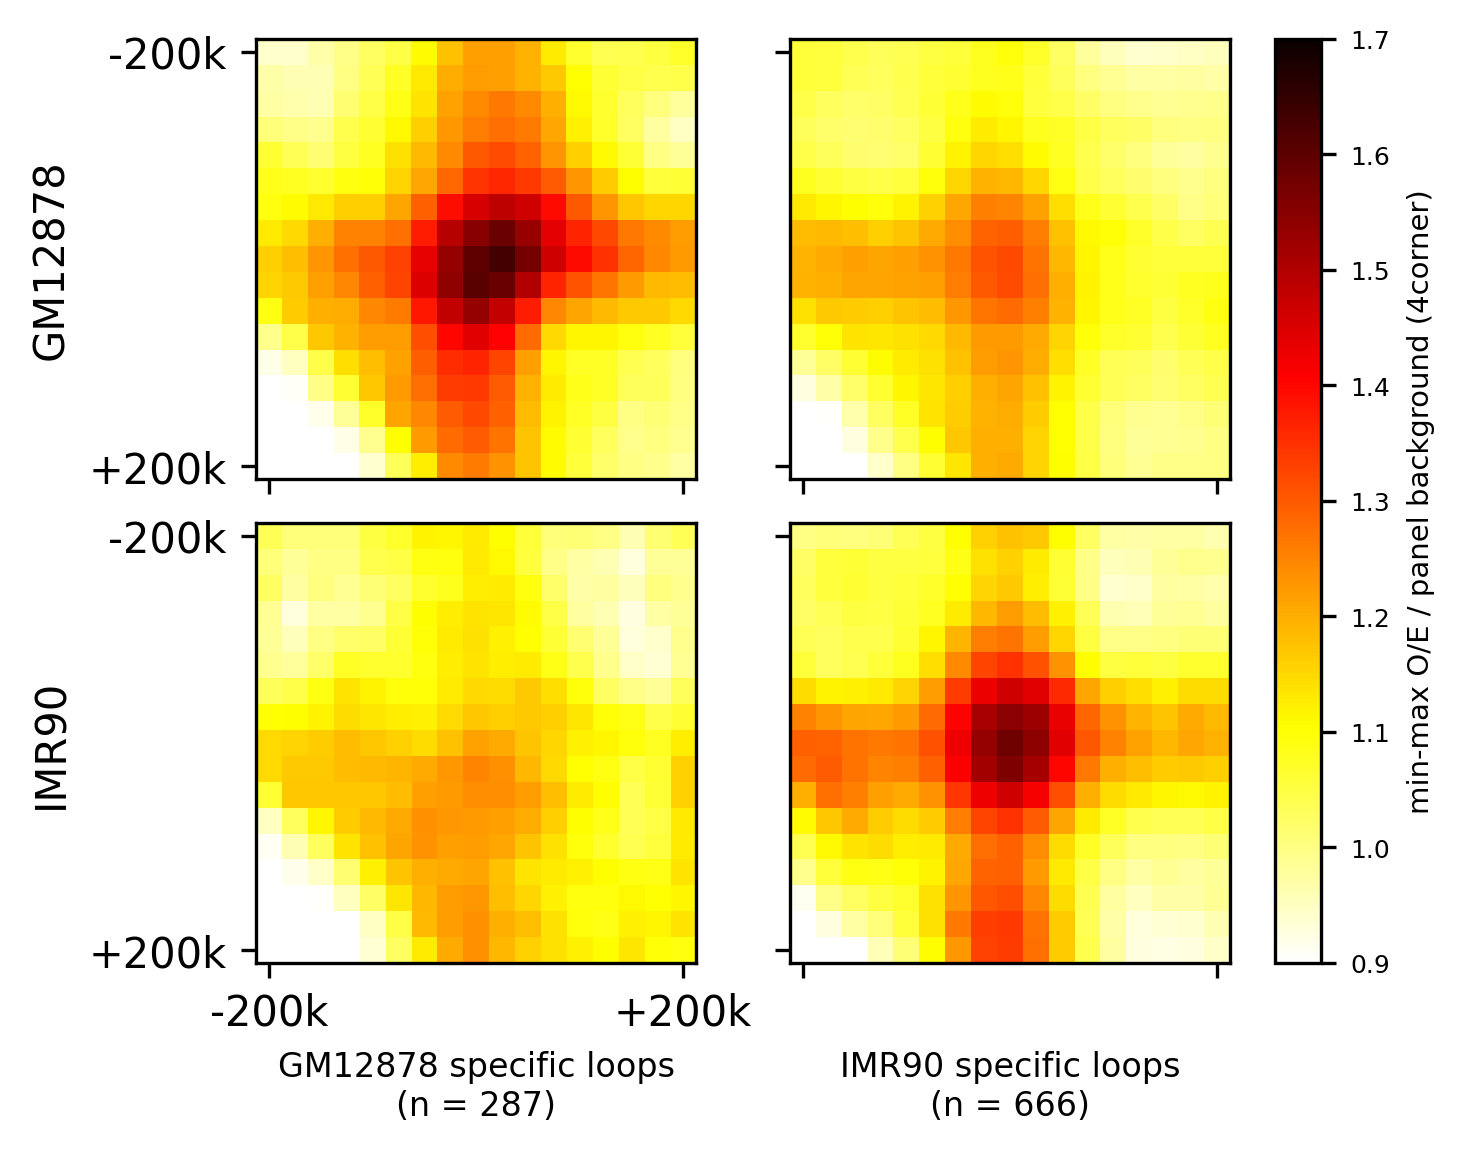

In [7]:
BG_MODE = "4corner"        # "4corner" (recommended) or "lowerleft" (juicer P2LL convention)


def panel_bg(p, mode=BG_MODE, b=BG_WIDTH):
    '''One scalar per panel: the background level to divide it by.'''
    ll = p[-b:, :b].mean()
    if mode == "lowerleft":
        return ll
    if mode == "4corner":
        return np.mean([p[:b, :b].mean(), p[:b, -b:].mean(), ll, p[-b:, -b:].mean()])
    raise ValueError(mode)


vis_bn = np.empty_like(vis_all)
score_bn = np.zeros((n_rows, n_cols))
for i in range(n_rows):
    for j in range(n_cols):
        bg = panel_bg(vis_all[i, j])
        vis_bn[i, j] = vis_all[i, j] / bg
        score_bn[i, j] = vis_all[i, j][apa_flank_bins, apa_flank_bins] / bg

bn_lo, bn_hi = float(np.nanmin(vis_bn)), float(np.nanmax(vis_bn))
print(f"BG_MODE = {BG_MODE}   normalised range {bn_lo:.2f} - {bn_hi:.2f}   (1.0 = panel background)")
print("\ncorner spread per panel (how much the four corners disagree):")
for i in range(n_rows):
    for j in range(n_cols):
        p = vis_all[i, j]; b = BG_WIDTH
        cs = [p[:b, :b].mean(), p[:b, -b:].mean(), p[-b:, :b].mean(), p[-b:, -b:].mean()]
        print(f"  {loop_labels[j].split()[0] + '-loops on ' + celltypes[i]:<28s} "
              f"{(max(cs) - min(cs)) / np.mean(cs):>6.1%}")

fig = draw(vis_bn, score_bn, score_mm, BG_MODE, "vs lower-left",
           f"min-max O/E / panel background ({BG_MODE})",
           vmin=0.9, vmax=float(np.ceil(bn_hi * 10) / 10),
           out_base=f"{FIG_BASE}_bgnorm")
plt.show()